# 14 · Analisis Error Lanjutan: Di Mana Sisa Error Ensemble Kita?

Pertanyaan yang dijawab:
1. Error terjadi di mana: segmen apa, zona skor mana, dan seberapa banyak yang "terlewat" vs "alarm palsu"?
2. Seperti apa nasabah yang salah ditebak, dibanding yang benar ditebak?
3. Apakah **masih ada informasi di fitur** yang belum dipakai model? Diuji dengan tiga cara: residu per desil fitur, *boosting* residu di dalam zona skor, dan kalibrasi per klaster.
4. Kalau ingin menaikkan KS, perbaikan di bagian mana yang **benar-benar berpengaruh**?

Skor yang dianalisis: rata-rata probabilitas OOF 4 anggota ensemble saat ini (`lgbm_tuned`, `xgb_v1`, `cat_v1`, `logreg_v1`), rata-rata 3 seed. Urutannya praktis sama dengan rata-rata peringkat sub_v4, tapi skala probabilitasnya tetap ada, jadi residu dan kalibrasi bisa dihitung.

Waktu jalan ± 5–10 menit. Tidak ada model ensemble yang dilatih ulang; hanya uji boosting residu di bagian 4.

In [1]:
import json
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.stats import chi2
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

import eda_utils as E
import modeling as M

warnings.simplefilter("ignore")
E.setup_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(50)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_tbl_cols(14)

meta = json.loads((M.FEAT_DIR / "features_v1.json").read_text())
FEAT, CATS = meta["features"], meta["categorical"]
NUM = [c for c in FEAT if c not in CATS]
train = pl.read_parquet(M.FEAT_DIR / "train_v1.parquet")
y = train["target"].to_numpy()
SEG = train["segment"].to_numpy()
SEEDS = [42, 7, 2024]
R = {k: M.run_from_disk(v, y) for k, v in {"lgbm": "lgbm_tuned", "xgb": "xgb_v1", "cat": "cat_v1", "logreg": "logreg_v1"}.items()}
p = np.mean([np.mean([R[k]["oof_by_seed"][s] for s in SEEDS], axis=0) for k in R], axis=0)
logit = lambda q: np.log(np.clip(q, 1e-6, 1 - 1e-6) / (1 - np.clip(q, 1e-6, 1 - 1e-6)))

order = np.argsort(-p)
yb = y[order]
TPR, FPR = np.cumsum(yb) / yb.sum(), np.cumsum(1 - yb) / (1 - yb).sum()
K = int(np.argmax(TPR - FPR))
THR = p[order][K]
FLAG = p >= THR                                    # ditandai berisiko pada ambang KS
RANK = np.empty(len(p)); RANK[order] = np.arange(len(p)) / len(p)    # 0 = paling berisiko
print(f"KS skor {M.ks_score(y, p):.4f} (rata-rata peringkat sub_v4: {M.blend(R, y, seeds=SEEDS)['ks_oof']:.4f})")
print(f"Ambang KS: menandai {FLAG.mean():.1%} nasabah paling berisiko | TPR {TPR[K]:.3f} | FPR {FPR[K]:.3f}")
print(f"Bad terlewat (di bawah ambang): {((~FLAG) & (y == 1)).sum():,} = {1 - TPR[K]:.1%} dari semua bad")
print(f"Alarm palsu (good di atas ambang): {(FLAG & (y == 0)).sum():,} = {FPR[K]:.1%} dari semua good")

KS skor 0.5254 (rata-rata peringkat sub_v4: 0.5254)
Ambang KS: menandai 32.7% nasabah paling berisiko | TPR 0.781 | FPR 0.255
Bad terlewat (di bawah ambang): 2,086 = 21.9% dari semua bad
Alarm palsu (good di atas ambang): 15,436 = 25.5% dari semua good


## 1. Komposisi error per segmen dan per desil skor

In [2]:
rows = []
for g in np.unique(SEG):
    m = SEG == g
    rows.append(dict(segmen=g, n=int(m.sum()), porsi_bad_total=(m & (y == 1)).sum() / y.sum(), bad_rate=y[m].mean(),
                     ks_dalam=M.ks_score(y[m], p[m]),
                     tpr=(FLAG & m & (y == 1)).sum() / (m & (y == 1)).sum(), fpr=(FLAG & m & (y == 0)).sum() / (m & (y == 0)).sum(),
                     porsi_bad_terlewat=((~FLAG) & m & (y == 1)).sum() / ((~FLAG) & (y == 1)).sum(),
                     porsi_alarm_palsu=(FLAG & m & (y == 0)).sum() / (FLAG & (y == 0)).sum()))
pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(3))

segmen,n,porsi_bad_total,bad_rate,ks_dalam,tpr,fpr,porsi_bad_terlewat,porsi_alarm_palsu
str,i64,f64,f64,f64,f64,f64,f64,f64
"""A_no_history""",21000,0.259,0.117,0.496,0.73,0.242,0.318,0.291
"""B_apps_no_installments""",2688,0.044,0.155,0.531,0.825,0.318,0.035,0.047
"""C_has_installments""",46312,0.697,0.143,0.539,0.797,0.258,0.647,0.663


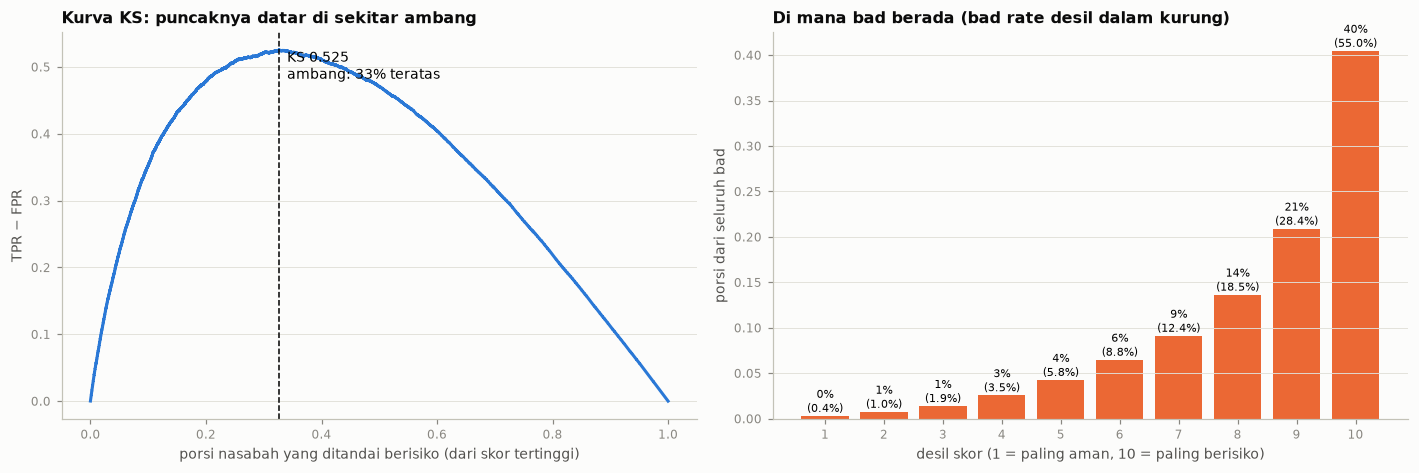

desil,n,prediksi,aktual,jumlah_bad,porsi_bad
i64,u32,f64,f64,i64,f64
1,7000,0.0071,0.0043,30,0.0032
2,7000,0.0156,0.0104,73,0.0077
3,7000,0.0255,0.019,133,0.014
4,7000,0.0383,0.0351,246,0.0259
5,7000,0.0559,0.058,406,0.0427
6,7000,0.0816,0.0881,617,0.0649
7,7000,0.1196,0.124,868,0.0913
8,7000,0.1799,0.1854,1298,0.1365
9,7000,0.2861,0.284,1988,0.2091


In [3]:
dec = np.ceil((RANK.size - np.argsort(np.argsort(p))) * 10 / RANK.size).astype(int)   # 1 = paling berisiko
dec = 11 - dec                                                                      # 1 = paling aman
cal = (pl.DataFrame({"desil": dec, "p": p, "y": y}).group_by("desil")
         .agg(n=pl.len(), prediksi=pl.col("p").mean(), aktual=pl.col("y").mean(), jumlah_bad=pl.col("y").sum())
         .sort("desil").with_columns(porsi_bad=pl.col("jumlah_bad") / y.sum()))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].plot(np.arange(len(p)) / len(p), TPR - FPR, color=E.SERIES[0], lw=2)
ax[0].axvline((K + 1) / len(p), color="black", ls="--", lw=1)
ax[0].text((K + 1) / len(p), (TPR - FPR)[K], f"  KS {(TPR - FPR)[K]:.3f}\n  ambang: {FLAG.mean():.0%} teratas", va="top", fontsize=9)
ax[0].set_xlabel("porsi nasabah yang ditandai berisiko (dari skor tertinggi)"); ax[0].set_ylabel("TPR − FPR")
ax[0].set_title("Kurva KS: puncaknya datar di sekitar ambang", loc="left")
ax[1].bar(cal["desil"], cal["porsi_bad"], color=E.SERIES[1])
for d, v, a in zip(cal["desil"], cal["porsi_bad"], cal["aktual"]):
    ax[1].text(d, v, f"{v:.0%}\n({a:.1%})", ha="center", va="bottom", fontsize=7.5)
ax[1].set_xticks(range(1, 11)); ax[1].set_xlabel("desil skor (1 = paling aman, 10 = paling berisiko)")
ax[1].set_ylabel("porsi dari seluruh bad"); ax[1].set_title("Di mana bad berada (bad rate desil dalam kurung)", loc="left")
plt.tight_layout(); plt.show()
cal.with_columns(pl.col(pl.Float64).round(4))

## 2. Seperti apa nasabah yang salah ditebak?

Perbandingan memakai **beda rata-rata terstandar (SMD)**: selisih rata-rata dibagi simpangan baku gabungan. |SMD| ≥ 0,5 berarti beda besar; < 0,1 praktis sama.
- **C1:** bad yang *terlewat* vs bad yang *tertangkap*. Apa yang membuat seorang bad terlihat aman?
- **C2:** bad yang terlewat vs **good di zona skor yang sama** (di bawah ambang). Kalau SMD kecil di semua fitur, keduanya memang tidak bisa dibedakan dengan data ini.

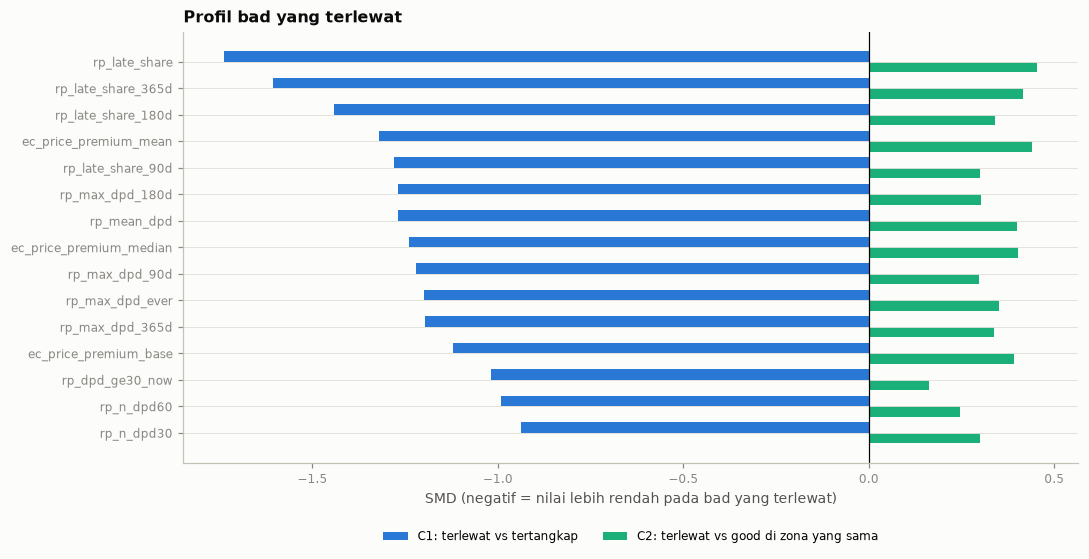

median |SMD| di semua fitur — C1: 0.192 | C2: 0.069


In [4]:
Xn = train.select(NUM).cast(pl.Float64).to_numpy()
def smd(a, b):
    ma, mb, sa, sb = np.nanmean(a, 0), np.nanmean(b, 0), np.nanstd(a, 0), np.nanstd(b, 0)
    return (ma - mb) / np.sqrt((sa ** 2 + sb ** 2) / 2 + 1e-12)
miss, caught, low_good = (~FLAG) & (y == 1), FLAG & (y == 1), (~FLAG) & (y == 0)
s1, s2 = np.nan_to_num(smd(Xn[miss], Xn[caught])), np.nan_to_num(smd(Xn[miss], Xn[low_good]))
top = np.argsort(-np.abs(s1))[:15]
fig, ax = plt.subplots(figsize=(10, 5.2))
yy = np.arange(len(top))
ax.barh(yy - 0.2, s1[top], height=0.4, color=E.SERIES[0], label="C1: terlewat vs tertangkap")
ax.barh(yy + 0.2, s2[top], height=0.4, color=E.SERIES[2], label="C2: terlewat vs good di zona yang sama")
ax.set_yticks(yy, [NUM[i] for i in top]); ax.invert_yaxis(); ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("SMD (negatif = nilai lebih rendah pada bad yang terlewat)")
ax.set_title("Profil bad yang terlewat", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8)
plt.tight_layout(); plt.show()
print(f"median |SMD| di semua fitur — C1: {np.median(np.abs(s1)):.3f} | C2: {np.median(np.abs(s2)):.3f}")

In [5]:
cols = [c for c in ["segment", "bu_score_mean", "rp_late_share", "rp_max_dpd_ever", "ec_price_premium_mean", "dti",
                    "declared_monthly_income", "ac_low_days_share_6m", "age"] if c in train.columns]
D = train.select(cols).with_columns(p=pl.Series(p).round(4), y=pl.Series(y))
print("Bad dengan prediksi PALING RENDAH (gagal bayar yang paling tidak terduga):")
display(D.filter(pl.col("y") == 1).sort("p").head(10).with_columns(pl.col(pl.Float64).round(3)))
print("Good dengan prediksi PALING TINGGI (alarm palsu yang paling yakin):")
display(D.filter(pl.col("y") == 0).sort("p", descending=True).head(10).with_columns(pl.col(pl.Float64).round(3)))

Bad dengan prediksi PALING RENDAH (gagal bayar yang paling tidak terduga):


segment,bu_score_mean,rp_late_share,rp_max_dpd_ever,ec_price_premium_mean,dti,declared_monthly_income,ac_low_days_share_6m,age,p,y
str,f64,f64,i32,f64,f64,i64,f64,i32,f64,i8
"""C_has_installments""",755.5,0.0,0,-0.224,0.162,8324512,0.0,25,0.005,1
"""A_no_history""",731.0,null,null,-0.219,0.171,6520541,null,43,0.005,1
"""C_has_installments""",631.5,0.0,0,-0.463,0.191,15301043,0.179,37,0.005,1
"""C_has_installments""",718.0,0.0,0,-0.28,0.218,9810506,0.0,27,0.006,1
"""C_has_installments""",731.333,0.028,30,-0.234,0.262,11218653,0.0,31,0.007,1
"""C_has_installments""",753.333,0.25,30,-0.076,0.301,8802976,0.0,50,0.007,1
"""C_has_installments""",657.5,0.037,30,-0.353,0.2,5083165,0.0,38,0.008,1
"""A_no_history""",712.0,null,null,-0.376,0.301,9280322,null,58,0.008,1
"""C_has_installments""",700.0,0.0,0,-0.428,0.339,2973116,0.0,42,0.008,1


Good dengan prediksi PALING TINGGI (alarm palsu yang paling yakin):


segment,bu_score_mean,rp_late_share,rp_max_dpd_ever,ec_price_premium_mean,dti,declared_monthly_income,ac_low_days_share_6m,age,p,y
str,f64,f64,i32,f64,f64,i64,f64,i32,f64,i8
"""C_has_installments""",595.333,0.958,244,0.546,0.321,9818174,0.0,46,0.94,0
"""C_has_installments""",531.667,0.935,334,0.531,0.325,5005910,0.0,49,0.934,0
"""C_has_installments""",581.667,0.812,180,0.422,0.281,8379476,0.0,40,0.922,0
"""C_has_installments""",561.333,0.914,269,0.555,0.225,14525201,0.0,29,0.907,0
"""C_has_installments""",659.5,0.938,152,0.9,0.277,27811439,0.093,55,0.907,0
"""C_has_installments""",530.5,0.9,152,0.251,0.396,5630003,0.0,59,0.904,0
"""C_has_installments""",548.5,0.978,455,0.501,0.185,6282625,0.0,32,0.898,0
"""C_has_installments""",568.333,0.846,182,0.666,0.384,7345079,0.071,23,0.898,0
"""C_has_installments""",614.5,1.0,272,0.866,0.295,2031444,0.0,45,0.897,0


## 3. Apakah model melewatkan pola di fitur? Residu per desil fitur

Untuk setiap fitur numerik, baris dibagi ke 10 desil fitur itu, lalu dihitung rata-rata residu (aktual − prediksi) per desil. Kalau model melewatkan pola, misalnya kurva yang tidak tertangkap, residunya akan menyimpang secara sistematis di beberapa desil. Uji chi-square memakai varians binomial dari prediksi. Ada ± 180 fitur yang diuji, jadi ambang signifikansinya dikoreksi Bonferroni.

In [6]:
res = y - p
rows = []
for j, c in enumerate(NUM):
    x = Xn[:, j]; m = ~np.isnan(x)
    if m.sum() < 5000 or np.unique(x[m]).size < 5:
        continue
    q = np.quantile(x[m], np.linspace(0, 1, 11))
    b = np.clip(np.searchsorted(q, x[m], side="right") - 1, 0, 9)
    z2, worst, nb = 0.0, 0.0, 0
    for k in range(10):
        sel = b == k
        if sel.sum() < 200:
            continue
        se = np.sqrt((p[m][sel] * (1 - p[m][sel])).sum()) / sel.sum()
        z2 += (res[m][sel].mean() / se) ** 2; nb += 1
        worst = max(worst, abs(res[m][sel].mean()))
    rows.append(dict(fitur=c, chi2=z2, p_value=1 - chi2.cdf(z2, nb), selisih_terbesar_per_desil=worst))
RES = pl.DataFrame(rows).sort("chi2", descending=True)
BONF = 0.05 / RES.height
print(f"{RES.height} fitur diuji | signifikan setelah Bonferroni (p < {BONF:.5f}): {RES.filter(pl.col('p_value') < BONF).height}")
RES.head(10).with_columns(pl.col(pl.Float64).round(4))

178 fitur diuji | signifikan setelah Bonferroni (p < 0.00028): 0


fitur,chi2,p_value,selisih_terbesar_per_desil
str,f64,f64,f64
"""ac_net_after_installment""",19.1671,0.0382,0.0098
"""ec_spend_180d""",16.2583,0.0925,0.0112
"""pa_max_requested""",16.2239,0.0934,0.0107
"""ac_last_closing""",13.8932,0.1779,0.0119
"""ec_spend_90d""",13.4806,0.198,0.0058
"""ac_outflow_all""",12.131,0.2764,0.0072
"""age""",11.829,0.2967,0.0071
"""ec_n_180d""",11.6812,0.307,0.0063
"""bu_hist_inq_mean""",11.6497,0.3092,0.008


## 4. Uji paling ketat: *boosting* residu di dalam zona skor

LightGBM dilatih **mulai dari skor ensemble** (`init_score` = logit skor), dengan CV 5 fold, untuk mencari sisa pola apa pun di semua fitur, termasuk interaksi. Uji dijalankan di tiga wilayah: zona di bawah ambang (dinilai aman), zona di atas ambang, dan semua baris. Kalau AUC dan KS tidak naik, fitur kita sudah habis dipakai.

In [7]:
levels = {c: sorted(set(train[c].drop_nulls().to_list())) for c in CATS}
X = M._to_pandas(train, FEAT, levels)
PB = dict(objective="binary", learning_rate=0.03, num_leaves=7, min_child_samples=300, colsample_bytree=0.3, subsample=0.8,
          subsample_freq=1, reg_lambda=10, n_estimators=3000, verbose=-1)
def residual_boost(mask):
    idx = np.flatnonzero(mask); yy = y[idx]; out = np.zeros(len(idx)); iters = []
    for a, b in StratifiedKFold(5, shuffle=True, random_state=0).split(idx, yy):
        m = lgb.LGBMClassifier(**PB).fit(X.iloc[idx[a]], yy[a], init_score=logit(p[idx[a]]),
                                         eval_set=[(X.iloc[idx[b]], yy[b])], eval_init_score=[logit(p[idx[b]])],
                                         eval_metric="auc", callbacks=[lgb.early_stopping(100, verbose=False)])
        out[b] = m.predict(X.iloc[idx[b]], raw_score=True) + logit(p[idx[b]]); iters.append(m.best_iteration_)
    return idx, out, iters
rows = []
for name, mask in (("zona bawah ambang (dinilai aman)", ~FLAG), ("zona atas ambang (dinilai berisiko)", FLAG),
                   ("semua baris", np.ones(len(y), bool))):
    idx, out, iters = residual_boost(mask)
    rows.append(dict(wilayah=name, n=len(idx), bad_rate=y[idx].mean(), auc_ensemble=roc_auc_score(y[idx], p[idx]),
                     auc_plus_boosting=roc_auc_score(y[idx], out), iterasi_median=int(np.median(iters)),
                     ks_ensemble=M.ks_score(y[idx], p[idx]), ks_plus_boosting=M.ks_score(y[idx], out)))
pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4))

wilayah,n,bad_rate,auc_ensemble,auc_plus_boosting,iterasi_median,ks_ensemble,ks_plus_boosting
str,i64,f64,f64,f64,i64,f64,f64
"""zona bawah ambang (dinilai aman)""",47143,0.0442,0.7429,0.743,2,0.382,0.3827
"""zona atas ambang (dinilai berisiko)""",22857,0.3247,0.7109,0.7109,1,0.3246,0.3248
"""semua baris""",70000,0.1358,0.8444,0.8444,1,0.5254,0.5252


## 5. Ketidaksepakatan antar model dan ketersediaan data

In [8]:
ranks = np.vstack([M.rank01(np.mean([R[k]["oof_by_seed"][s] for s in SEEDS], axis=0)) for k in R])
dis = ranks.std(0)
q50, q90 = np.quantile(dis, [0.5, 0.9])
rows = []
for name, m in (("sepakat (50% terbawah)", dis <= q50), ("agak beda", (dis > q50) & (dis <= q90)), ("sangat beda (10% teratas)", dis > q90)):
    rows.append(dict(ketidaksepakatan=name, n=int(m.sum()), bad_rate=y[m].mean(), ks_dalam=M.ks_score(y[m], p[m]),
                     rata2_abs_residu=np.abs(y[m] - p[m]).mean()))
display(pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4)))
print(f"korelasi |residu| dengan ketidaksepakatan antar model: {np.corrcoef(dis, np.abs(y - p))[0, 1]:.3f}")

grp = train.select(rekening=pl.when(pl.col("ac_n_months").is_null()).then(pl.lit("tanpa data rekening")).otherwise(pl.lit("ada data rekening")),
                   ecom=pl.when(pl.col("ec_n_orders_all") < 20).then(pl.lit("< 20 order e-commerce")).otherwise(pl.lit("≥ 20 order e-commerce")),
                   biro=pl.when(pl.col("bu_n_unscored") > 0).then(pl.lit("ada laporan biro tanpa skor")).otherwise(pl.lit("semua laporan berskor")))
rows = []
for k in grp.columns:
    for v in grp[k].unique().sort().to_list():
        m = (grp[k] == v).to_numpy()
        rows.append(dict(dimensi=k, grup=v, n=int(m.sum()), bad_rate=y[m].mean(), ks_dalam=M.ks_score(y[m], p[m])))
pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4))

ketidaksepakatan,n,bad_rate,ks_dalam,rata2_abs_residu
str,i64,f64,f64,f64
"""sepakat (50% terbawah)""",35000,0.1881,0.5616,0.217
"""agak beda""",28000,0.0878,0.4111,0.1445
"""sangat beda (10% teratas)""",7000,0.0666,0.3193,0.1247


korelasi |residu| dengan ketidaksepakatan antar model: -0.163


dimensi,grup,n,bad_rate,ks_dalam
str,str,i64,f64,f64
"""rekening""","""ada data rekening""",49000,0.1438,0.5372
"""rekening""","""tanpa data rekening""",21000,0.1172,0.4958
"""ecom""","""< 20 order e-commerce""",12508,0.1398,0.5193
"""ecom""","""≥ 20 order e-commerce""",57492,0.135,0.5269
"""biro""","""ada laporan biro tanpa skor""",9617,0.1317,0.5331
"""biro""","""semua laporan berskor""",60383,0.1365,0.5248


## 6. Perbaikan di mana yang benar-benar menaikkan KS?

Simulasi ini tidak melatih model apa pun. Urutan **di dalam satu grup saja** dibuat sedikit lebih baik dengan menggeser skor bad naik dan skor good turun, sampai KS di dalam grup itu naik 0,02. Lalu diukur berapa KS total ikut naik. Hasilnya menunjukkan bagian mana yang paling "berharga" untuk diperbaiki.

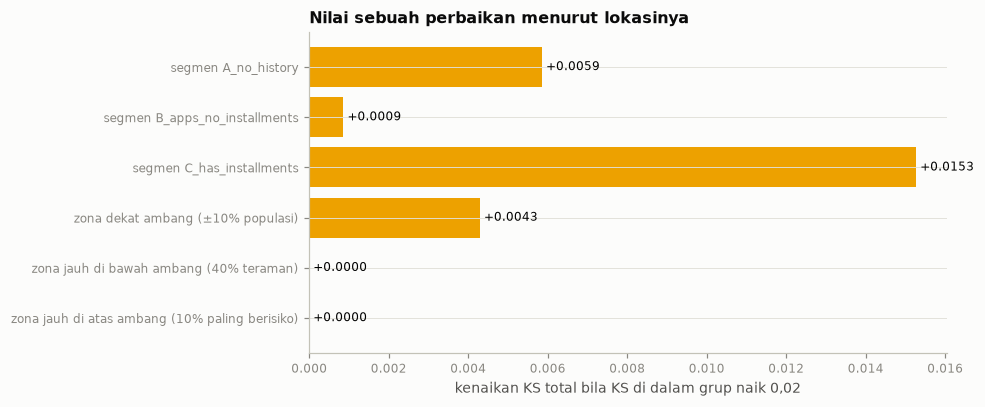

grup,n,porsi_bad,ks_dalam,ks_total_naik
str,i64,f64,f64,f64
"""segmen A_no_history""",21000,0.2589,0.4958,0.0059
"""segmen B_apps_no_installments""",2688,0.0439,0.5307,0.0009
"""segmen C_has_installments""",46312,0.6973,0.5388,0.0153
"""zona dekat ambang (±10% populasi)""",14000,0.2056,0.13,0.0043
"""zona jauh di bawah ambang (40% teraman)""",27999,0.0507,0.3181,0.0
"""zona jauh di atas ambang (10% paling berisiko)""",7000,0.4048,0.2272,0.0


In [9]:
LG, BASE = logit(p), M.ks_score(y, logit(p))
def improve(mask, gain=0.02):
    ks0 = M.ks_score(y[mask], LG[mask])
    for d in np.linspace(0.01, 1.5, 150):
        z = LG.copy(); z[mask] += d * (2 * y[mask] - 1)
        if M.ks_score(y[mask], z[mask]) - ks0 >= gain:
            return M.ks_score(y, z) - BASE
    return np.nan
THR_R = (K + 1) / len(p)
G = {f"segmen {g}": SEG == g for g in np.unique(SEG)}
G.update({"zona dekat ambang (±10% populasi)": np.abs(RANK - THR_R) < 0.10,
          "zona jauh di bawah ambang (40% teraman)": RANK > 0.60,
          "zona jauh di atas ambang (10% paling berisiko)": RANK < 0.10})
rows = [dict(grup=n, n=int(m.sum()), porsi_bad=y[m].sum() / y.sum(), ks_dalam=M.ks_score(y[m], p[m]),
             ks_total_naik=improve(m)) for n, m in G.items()]
SENS = pl.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(SENS["grup"], SENS["ks_total_naik"], color=E.SERIES[3]); ax.invert_yaxis()
for i, v in enumerate(SENS["ks_total_naik"]):
    ax.text(v, i, f" +{v:.4f}", va="center", fontsize=8)
ax.set_xlabel("kenaikan KS total bila KS di dalam grup naik 0,02"); ax.set_title("Nilai sebuah perbaikan menurut lokasinya", loc="left")
plt.tight_layout(); plt.show()
SENS.with_columns(pl.col(pl.Float64).round(4))